# Distribución geográfica de las observaciones de la rana de ojos rojos (*Agalychnis callidryas*) en los cantones de Costa Rica

**Autor:** Jarod Salas Díaz
**Curso:** GF-0657 Programación en SIG — II ciclo 2026
**Tarea 3:** datos geoespaciales con geopandas

---

## 1. Introducción

La rana de ojos rojos (*Agalychnis callidryas*) es un anfibio arborícola de las tierras bajas húmedas de
Mesoamérica y uno de los animales más fotografiados de Costa Rica. En la tarea 2 se analizaron sus registros
de ciencia ciudadana en iNaturalist con pandas (tendencia anual, estacionalidad y distribución por provincia,
esta última extraída del texto del campo `place_guess`). En esta tarea se aprovechan las **coordenadas** de cada
observación: la tabla se convierte en una capa de puntos y se relaciona espacialmente con los cantones del
Instituto Geográfico Nacional (IGN), lo que permite asignar cada registro al cantón donde cae de forma exacta.

### Preguntas

1. **¿Dónde** se concentran las observaciones de *A. callidryas*? ¿Cuáles cantones acumulan más registros? *(geográfica)*
2. **¿Cuántas observaciones hay por unidad de área** en cada cantón (observaciones por 100 km²) y qué cantones no tienen registros? *(geográfica)*
3. **¿Cómo se reparten las observaciones entre las provincias** y qué tan concentrado está el esfuerzo de observación en pocos cantones? *(geográfica / de agregación)*

### Fuentes de datos

| Capa | Fuente | Formato | Geometría | SRC original | Variables principales |
|---|---|---|---|---|---|
| Observaciones de *A. callidryas* | iNaturalist (2026), descarga para Costa Rica | CSV con coordenadas | Puntos (creados a partir de `longitude`, `latitude`) | WGS84 (EPSG:4326) | `observed_on`, `quality_grade`, `positional_accuracy`, `coordinates_obscured`, `place_guess`, `user_login`, `uri` |
| Cantones de Costa Rica | IGN, vía repositorio del curso GF-0657 | GeoPackage | Multipolígonos (84 cantones) | CRTM05 (EPSG:8908) | `provincia`, `codigo_canton`, `canton` |
| Provincias de Costa Rica | IGN, vía repositorio del curso GF-0657 | GeoPackage | Multipolígonos (7 provincias) | CRTM05 (EPSG:8908) | `codigo_provincia`, `provincia` |

- iNaturalist. (2026). *Observaciones de* Agalychnis callidryas *en Costa Rica* [Conjunto de datos]. https://www.inaturalist.org/observations?place_id=6924&taxon_id=23702
- Instituto Geográfico Nacional. (2026). *Límites cantonales y provinciales de Costa Rica* [Conjunto de datos, distribuido en el repositorio del curso]. https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/ign

El CSV es el mismo de la tarea 2 y se carga desde el repositorio de esa tarea en GitHub; las capas del IGN se cargan desde el repositorio del curso.

## 2. Configuración

Bibliotecas: **pandas** para la tabla, **geopandas** para las capas vectoriales y las operaciones espaciales,
**mapclassify** para clasificar la variable del mapa de coropletas, **matplotlib** para el gráfico y el mapa estático
y **folium** para el mapa web interactivo. Todas vienen instaladas en Google Colab.

In [1]:
# En Colab todas estas bibliotecas ya están instaladas.
# Si mapclassify faltara, descomente la siguiente línea:
# !pip install mapclassify

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import mapclassify
import folium
from branca.colormap import StepColormap

import warnings
warnings.filterwarnings("ignore", message="Numba not installed")  # aviso informativo de mapclassify

pd.set_option("display.max_columns", 30)

In [2]:
# URLs de los datos (botón "Raw" de GitHub)
URL_OBSERVACIONES = (
    "https://raw.githubusercontent.com/jasalas2/tarea2_psig/main/"
    "agalychnis_callidryas_costa_rica_inaturalist.csv"
)
URL_CANTONES = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/ign/cantones.gpkg"
URL_PROVINCIAS = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/ign/provincias.gpkg"

# Sistemas de referencia de coordenadas que se usarán
SRC_CRTM05 = 8908   # CR-SIRGAS / CRTM05: proyectado, en metros (áreas y distancias)
SRC_WGS84 = 4326    # coordenadas geográficas: el que requieren los mapas web

## 3. Carga y preparación de las capas

Para que el código pueda reutilizarse en la aplicación web del proyecto final, la carga y la preparación de cada capa
se escriben como funciones.

### 3.1 Cantones y provincias (IGN)

In [3]:
def cargar_limites(url):
    '''Lee una capa de límites administrativos del IGN desde una URL.'''
    return gpd.read_file(url)

cantones = cargar_limites(URL_CANTONES)
provincias = cargar_limites(URL_PROVINCIAS)

# Exploración inicial
for nombre, capa in [("cantones", cantones), ("provincias", provincias)]:
    print(f"{nombre}: {len(capa)} filas | SRC: {capa.crs.name} (EPSG:{capa.crs.to_epsg()}) "
          f"| geometrías: {capa.geom_type.unique().tolist()}")

cantones.head()

cantones: 84 filas | SRC: CR-SIRGAS epoch 2014.59 / CRTM05 (EPSG:8908) | geometrías: ['MultiPolygon']
provincias: 7 filas | SRC: CR-SIRGAS epoch 2014.59 / CRTM05 (EPSG:8908) | geometrías: ['MultiPolygon']


,codigo_provincia,provincia,codigo_canton,canton,geometry
0,1,San José,101,San José,"MULTIPOLYGON (((481030.294 1102633.121, 481510..."
1,1,San José,102,Escazú,"MULTIPOLYGON (((479844.884 1102669.54, 479982...."
2,1,San José,103,Desamparados,"MULTIPOLYGON (((494091.189 1094936.765, 494448..."
3,1,San José,104,Puriscal,"MULTIPOLYGON (((455732.107 1095962.406, 456519..."
4,1,San José,105,Tarrazú,"MULTIPOLYGON (((501118.557 1074475.546, 502323..."


Ambas capas vienen en **CRTM05 (EPSG:8908)**, la proyección oficial de Costa Rica, en metros. Es el SRC adecuado para
calcular áreas y para la unión espacial, por lo que no se reproyectan en esta etapa. Se agrega a los cantones una
columna con su **área en km²** (el área de la geometría está en m², se divide entre 10⁶), necesaria para la densidad de
observaciones de la pregunta 2.

In [4]:
# Área de cada cantón en km² (calculada en CRTM05, que está en metros)
cantones["area_km2"] = cantones.geometry.area / 1e6
print(f"Área total de los cantones: {cantones['area_km2'].sum():,.0f} km²")
cantones[["provincia", "canton", "area_km2"]].sort_values("area_km2", ascending=False).head()

Área total de los cantones: 51,177 km²


,provincia,canton,area_km2
29,Alajuela,San Carlos,3352.280378
81,Limón,Talamanca,2793.205329
67,Puntarenas,Buenos Aires,2382.634119
79,Limón,Pococí,2188.658022
53,Heredia,Sarapiquí,2143.257011


### 3.2 Observaciones de iNaturalist: de tabla a capa de puntos

In [5]:
obs = pd.read_csv(URL_OBSERVACIONES, low_memory=False)
print(f"Filas: {len(obs):,} | columnas: {obs.shape[1]}")
print("\nGrado de calidad:")
print(obs["quality_grade"].value_counts())
print("\nCoordenadas ocultadas (coordinates_obscured):")
print(obs["coordinates_obscured"].value_counts())
print("\nPrecisión posicional (m):")
print(obs["positional_accuracy"].describe().round(1))

Filas: 9,799 | columnas: 23

Grado de calidad:
quality_grade
research    9206
needs_id     400
casual       193
Name: count, dtype: int64

Coordenadas ocultadas (coordinates_obscured):
coordinates_obscured
false       9372
obscured     416
true          11
Name: count, dtype: int64

Precisión posicional (m):
count        8222.0
mean         8343.8
std        256363.2
min             1.0
25%             6.0
50%            46.0
75%           343.8
max      22542190.0
Name: positional_accuracy, dtype: float64


La exploración muestra tres problemas para un análisis espacial:

- Hay registros que no son de **grado de investigación** (`needs_id`, `casual`): su identificación no está confirmada.
- Algunos registros tienen las **coordenadas ocultadas** (`obscured` o `true`): iNaturalist desplaza la posición
  aleatoriamente dentro de un cuadro de unos 20 km para proteger especies o sitios sensibles, por lo que no sirven para
  asignar el cantón.
- La **precisión posicional** va de 1 m a miles de kilómetros. Se conservan los registros con precisión ≤ 1000 m
  (o sin valor informado), un margen razonable para unidades del tamaño de un cantón.
- Como en la tarea 2, se descartan las fechas vacías o anteriores al año 2000 (hay fechas erróneas, como 1969-12-31).

La función `preparar_observaciones()` aplica estos filtros, convierte la fecha y crea la geometría de puntos con
`gpd.points_from_xy()` en WGS84 (el SRC en que vienen las coordenadas), para luego **reproyectarla a CRTM05**,
el mismo SRC de los cantones.

In [6]:
def preparar_observaciones(df, precision_max=1000):
    '''Filtra los registros confiables y los convierte en una capa de puntos en CRTM05.'''
    filtro = (
        (df["quality_grade"] == "research")
        & (df["coordinates_obscured"].astype(str).str.lower() == "false")
        & ((df["positional_accuracy"] <= precision_max) | df["positional_accuracy"].isna())
    )
    df = df.loc[filtro].copy()
    df["observed_on"] = pd.to_datetime(df["observed_on"], errors="coerce")
    df["anio"] = df["observed_on"].dt.year
    df = df[df["anio"] >= 2000]   # como en la tarea 2: se descartan fechas vacías o erróneas anteriores a 2000

    # Tabla -> capa de puntos (las coordenadas de iNaturalist están en WGS84)
    gdf = gpd.GeoDataFrame(
        df[["id", "observed_on", "anio", "place_guess", "user_login",
            "positional_accuracy", "uri", "latitude", "longitude"]],
        geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
        crs=SRC_WGS84,
    )
    return gdf.to_crs(SRC_CRTM05)   # reproyección al SRC de los cantones

puntos = preparar_observaciones(obs)
print(f"Observaciones confiables: {len(puntos):,} de {len(obs):,} ({len(puntos)/len(obs):.0%})")
print(f"SRC: {puntos.crs.name} (EPSG:{puntos.crs.to_epsg()}) | geometrías: {puntos.geom_type.unique().tolist()}")
print(f"Período: {puntos['observed_on'].min():%Y-%m-%d} a {puntos['observed_on'].max():%Y-%m-%d}")
puntos.head(3)

Observaciones confiables: 7,570 de 9,799 (77%)
SRC: CR-SIRGAS epoch 2014.59 / CRTM05 (EPSG:8908) | geometrías: ['Point']
Período: 2000-06-09 a 2026-10-09


,id,observed_on,anio,place_guess,user_login,positional_accuracy,uri,latitude,longitude,geometry
0,25161,2011-03-15,2011,"Las Cruces Biological Station, Coto Brus, Cost...",redpine,NaN,http://www.inaturalist.org/observations/25161,8.798141,-82.969694,POINT (613346.973 972983.057)
1,27488,2009-05-15,2009,"Tirimbina, Costa Rica",rahunt2,NaN,http://www.inaturalist.org/observations/27488,10.398960,-84.135063,POINT (485211.665 1149871.589)
3,53691,2009-11-13,2009,"Chilamate, Heredia, Costa Rica",matteo,NaN,http://www.inaturalist.org/observations/53691,10.450527,-84.068100,POINT (492544.818 1155572.535)


## 4. Operaciones espaciales

### 4.1 Unión espacial: ¿en qué cantón cae cada observación? (preguntas 1 y 2)

Se usa `gpd.sjoin()` con el predicado `within` para asignar a cada punto los atributos del cantón que lo contiene.
La operación se realiza en **CRTM05 (EPSG:8908)**: ambas capas deben compartir SRC y, al ser proyectado, es el mismo
sistema en que se calculan las áreas.

Algunos puntos quedan justo fuera de los polígonos (en la línea de costa, en manglares o en ríos limítrofes, por la
precisión del GPS o la generalización de los límites). Para esos casos se usa una segunda operación,
el **vecino más cercano** (`gpd.sjoin_nearest()`), con una distancia máxima de 2 km.

In [7]:
def asignar_canton(puntos, cantones, distancia_max=2000):
    '''Une cada punto con su cantón (within) y, si cae fuera, con el cantón más cercano a <= distancia_max m.'''
    columnas = ["provincia", "codigo_canton", "canton", "geometry"]
    unidos = gpd.sjoin(puntos, cantones[columnas], how="left", predicate="within")
    fuera = unidos["canton"].isna()
    print(f"Puntos dentro de un cantón: {(~fuera).sum():,} | fuera de los polígonos: {fuera.sum()}")

    # Vecino más cercano para los puntos que no cayeron dentro de ningún polígono
    cercanos = gpd.sjoin_nearest(
        puntos.loc[fuera], cantones[columnas], how="left",
        max_distance=distancia_max, distance_col="dist_m",
    )
    cercanos = cercanos[~cercanos.index.duplicated()]  # por si un punto equidista de dos cantones
    unidos.loc[fuera, ["provincia", "codigo_canton", "canton"]] = cercanos[["provincia", "codigo_canton", "canton"]]
    print(f"Recuperados con el vecino más cercano (≤ {distancia_max} m): {cercanos['canton'].notna().sum()}")
    print(f"Sin cantón (fuera de Costa Rica o a más de {distancia_max} m): {unidos['canton'].isna().sum()}")
    return unidos.drop(columns="index_right").dropna(subset=["canton"])

puntos_canton = asignar_canton(puntos, cantones)
puntos_canton[["observed_on", "place_guess", "provincia", "canton"]].head()

Puntos dentro de un cantón: 7,557 | fuera de los polígonos: 13
Recuperados con el vecino más cercano (≤ 2000 m): 11
Sin cantón (fuera de Costa Rica o a más de 2000 m): 2


,observed_on,place_guess,provincia,canton
0,2011-03-15,"Las Cruces Biological Station, Coto Brus, Cost...",Puntarenas,Coto Brus
1,2009-05-15,"Tirimbina, Costa Rica",Heredia,Sarapiquí
3,2009-11-13,"Chilamate, Heredia, Costa Rica",Heredia,Sarapiquí
5,2012-05-24,GVI Jalova Tortuguero National Park,Limón,Guácimo
9,2012-10-14,OTS La Selva,Heredia,Sarapiquí


Con el resultado se cuentan las observaciones por cantón y se unen (por atributo, con `merge`) de vuelta a la capa
de cantones. Los cantones sin observaciones quedan con conteo 0; la **densidad** se calcula como observaciones por
100 km².

In [8]:
def contar_por_canton(puntos_canton, cantones):
    '''Agrega el número de observaciones y la densidad (obs/100 km²) a la capa de cantones.'''
    conteo = puntos_canton.groupby("codigo_canton").size().rename("observaciones")
    capa = cantones.merge(conteo, left_on="codigo_canton", right_index=True, how="left")
    capa["observaciones"] = capa["observaciones"].fillna(0).astype(int)
    capa["densidad"] = capa["observaciones"] / capa["area_km2"] * 100
    return capa

cantones_obs = contar_por_canton(puntos_canton, cantones)
n_con = (cantones_obs["observaciones"] > 0).sum()
print(f"Cantones con al menos una observación: {n_con} de {len(cantones_obs)}")

Cantones con al menos una observación: 48 de 84


### 4.2 Agregación con `dissolve()`: observaciones por provincia (pregunta 3)

Para responder la pregunta 3 se disuelven los cantones por provincia con `dissolve()`, sumando las observaciones y el
área. Esto genera de nuevo los polígonos provinciales a partir de los cantonales, con los totales agregados. La operación
se realiza en **CRTM05**, así que el área sumada sigue en km².

In [9]:
provincias_obs = (
    cantones_obs[["provincia", "observaciones", "area_km2", "geometry"]]
    .dissolve(by="provincia", aggfunc="sum")
    .reset_index()
)
provincias_obs["densidad"] = provincias_obs["observaciones"] / provincias_obs["area_km2"] * 100
provincias_obs["porcentaje"] = provincias_obs["observaciones"] / provincias_obs["observaciones"].sum() * 100
provincias_obs = provincias_obs.sort_values("observaciones", ascending=False)

# Concentración: porcentaje de observaciones en los 5 y 10 cantones con más registros
orden = cantones_obs["observaciones"].sort_values(ascending=False)
total = orden.sum()
print(f"Los 5 cantones con más registros reúnen el {orden.head(5).sum()/total:.1%} de las observaciones.")
print(f"Los 10 cantones con más registros reúnen el {orden.head(10).sum()/total:.1%} de las observaciones.")

(provincias_obs.drop(columns="geometry")
 .style.format({"observaciones": "{:,}", "area_km2": "{:,.0f}", "densidad": "{:.1f}", "porcentaje": "{:.1f} %"})
 .hide(axis="index")
 .set_caption("Observaciones de A. callidryas por provincia (agregación con dissolve)"))

Los 5 cantones con más registros reúnen el 64.0% de las observaciones.
Los 10 cantones con más registros reúnen el 85.2% de las observaciones.


provincia,observaciones,area_km2,densidad,porcentaje
Alajuela,"2,876","9,773",29.4,38.0 %
Puntarenas,"1,519","11,302",13.4,20.1 %
Heredia,"1,488","2,662",55.9,19.7 %
Limón,"1,453","9,178",15.8,19.2 %
San José,85,"4,970",1.7,1.1 %
Cartago,79,"3,092",2.6,1.0 %
Guanacaste,68,"10,200",0.7,0.9 %


## 5. Tabla de resumen: cantones con más observaciones

In [10]:
top = (
    cantones_obs.sort_values("observaciones", ascending=False)
    .head(15)[["canton", "provincia", "observaciones", "area_km2", "densidad"]]
    .reset_index(drop=True)
)
top["porcentaje"] = top["observaciones"] / total * 100
top.index = top.index + 1  # posición 1-15

(top.rename(columns={
        "canton": "Cantón", "provincia": "Provincia", "observaciones": "Observaciones",
        "area_km2": "Área (km²)", "densidad": "Densidad (obs/100 km²)", "porcentaje": "% del total"})
    .style
    .format({"Observaciones": "{:,}", "Área (km²)": "{:,.0f}",
             "Densidad (obs/100 km²)": "{:.1f}", "% del total": "{:.1f} %"})
    .bar(subset=["Observaciones"], color="#9fd3a7")
    .set_caption("Los 15 cantones con más observaciones de A. callidryas (grado de investigación)"))

,Cantón,Provincia,Observaciones,Área (km²),Densidad (obs/100 km²),% del total
1,San Carlos,Alajuela,"1,860","3,352",55.5,24.6 %
2,Sarapiquí,Heredia,"1,482","2,143",69.1,19.6 %
3,Pococí,Limón,623,"2,189",28.5,8.2 %
4,Upala,Alajuela,463,"1,593",29.1,6.1 %
5,Talamanca,Limón,414,"2,793",14.8,5.5 %
6,San Ramón,Alajuela,408,"1,022",39.9,5.4 %
7,Quepos,Puntarenas,406,558,72.7,5.4 %
8,Puerto Jiménez,Puntarenas,359,721,49.8,4.7 %
9,Osa,Puntarenas,234,"1,933",12.1,3.1 %
10,Golfito,Puntarenas,196,"1,033",19.0,2.6 %


La tabla ordena los cantones por número de observaciones. **San Carlos** y **Sarapiquí**, en las llanuras del norte, encabezan la
lista y entre ambos reúnen más de 4 de cada 10 registros del país; les siguen cantones caribeños (Pococí, Talamanca, Limón,
Matina, Siquirres), la zona norte (Upala y San Ramón, cuyos distritos del norte, como Peñas Blancas, están en tierras bajas) y el Pacífico Central y Sur (Quepos, Puerto Jiménez, Osa, Golfito). La densidad matiza el
conteo: cantones pequeños como Quepos o Sarapiquí tienen muchos registros por km², mientras que San Carlos, el cantón más
extenso del país, ocupa un lugar más modesto cuando el conteo se divide entre su área.

## 6. Gráfico: observaciones por cantón

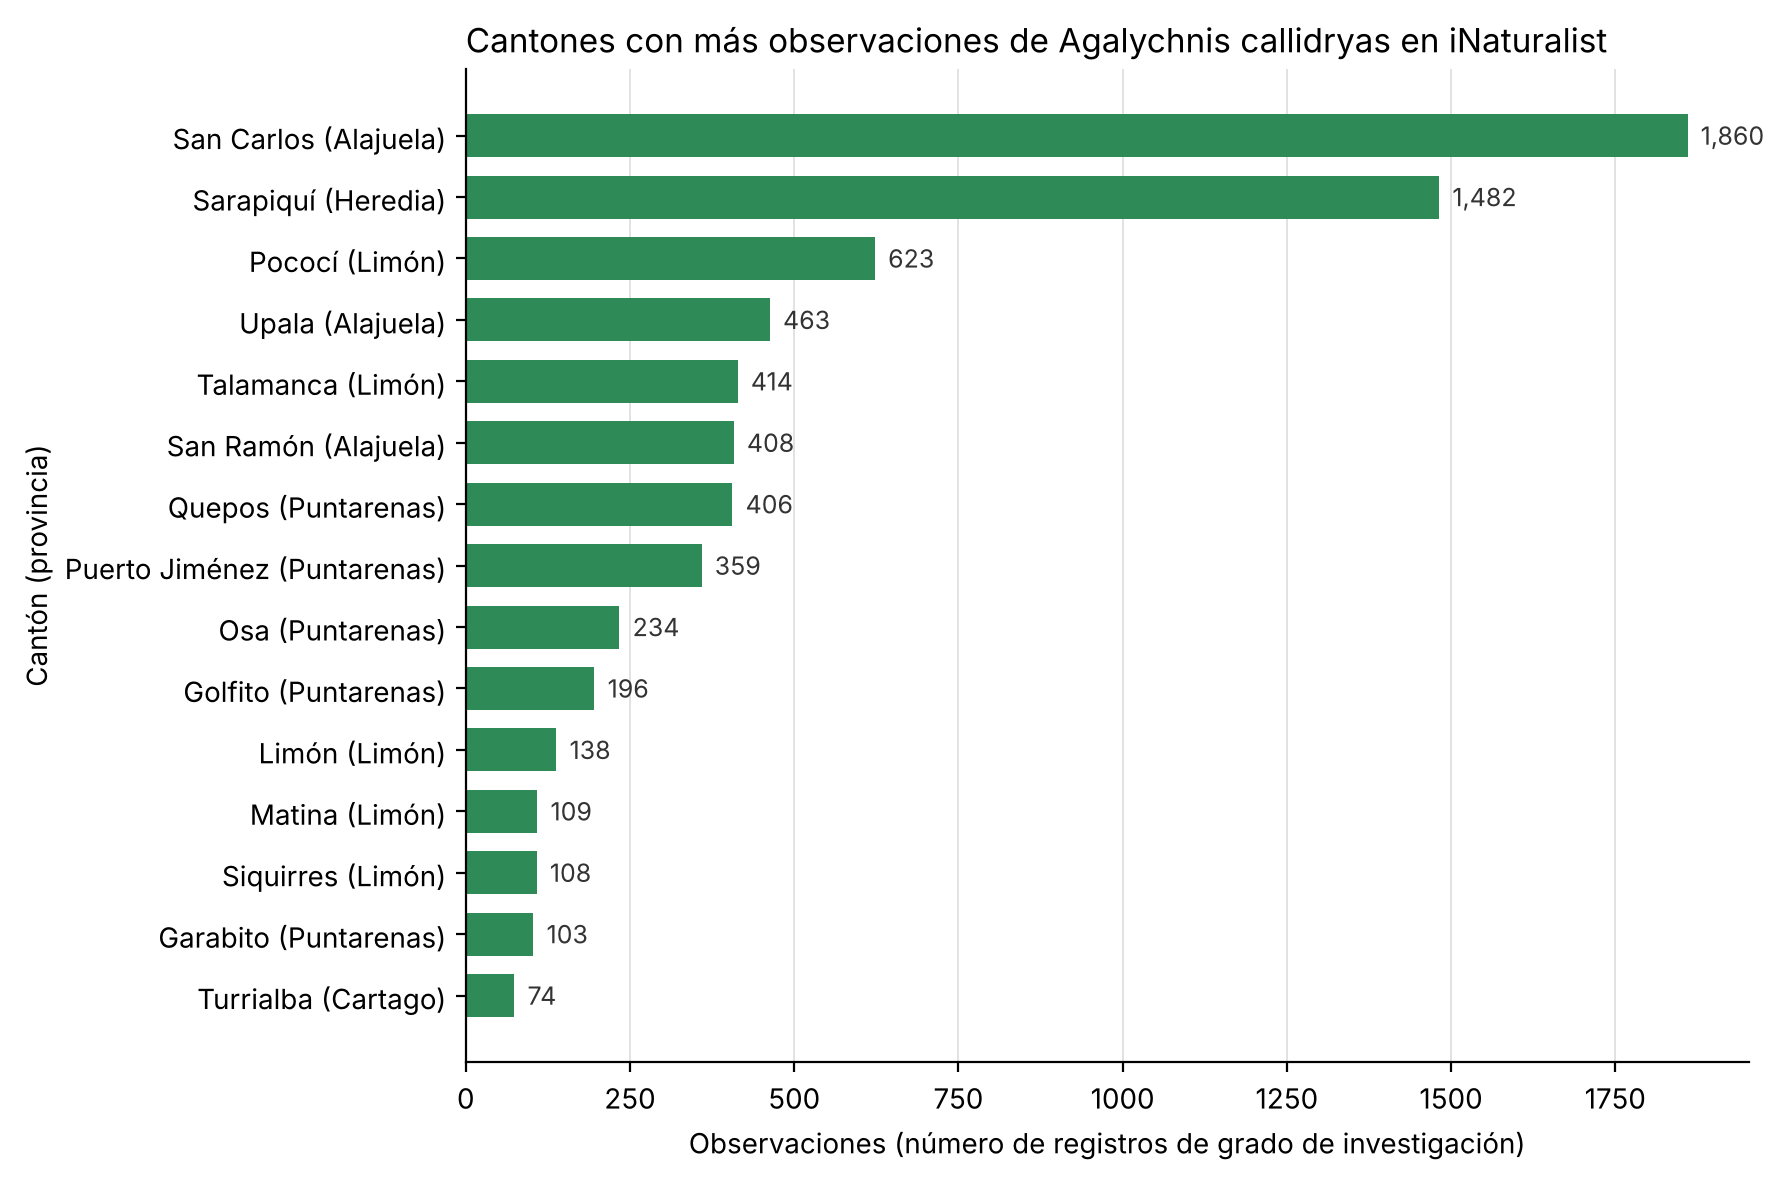

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
datos = top.sort_values("observaciones")  # de menor a mayor para que el mayor quede arriba
ax.barh(datos["canton"] + " (" + datos["provincia"] + ")", datos["observaciones"], color="#2e8b57", height=0.7)

# Etiqueta con el valor al final de cada barra
for y, v in enumerate(datos["observaciones"]):
    ax.text(v + 20, y, f"{v:,}", va="center", fontsize=9, color="#333333")

ax.set_title("Cantones con más observaciones de Agalychnis callidryas en iNaturalist", fontsize=12, loc="left")
ax.set_xlabel("Observaciones (número de registros de grado de investigación)")
ax.set_ylabel("Cantón (provincia)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#dddddd", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

El gráfico de barras horizontales es adecuado para comparar una magnitud (el conteo) entre categorías con nombres largos.
Muestra una distribución muy asimétrica: los dos primeros cantones superan con holgura al resto, y a partir del décimo
puesto los conteos caen por debajo de 200. Esto refleja tanto el hábitat de la especie (bosques húmedos de tierras bajas)
como el **esfuerzo de observación**: San Carlos (La Fortuna, Arenal) y Sarapiquí (La Selva, Puerto Viejo) concentran
estaciones biológicas, albergues y tours nocturnos donde la rana se busca y fotografía con frecuencia.

## 7. Mapa estático: densidad de observaciones por cantón

Mapa de coropletas de la **densidad** (observaciones por 100 km²), que, a diferencia del conteo, no favorece a los cantones
grandes. Como la variable es muy asimétrica (muchos cantones con valores bajos y unos pocos muy altos), se clasifica con
el método de **cortes naturales de Fisher-Jenks** (5 clases) y una escala secuencial de un solo tono (claro = baja,
oscuro = alta). Los cantones **sin observaciones** se muestran en gris. Encima se dibujan los límites provinciales.

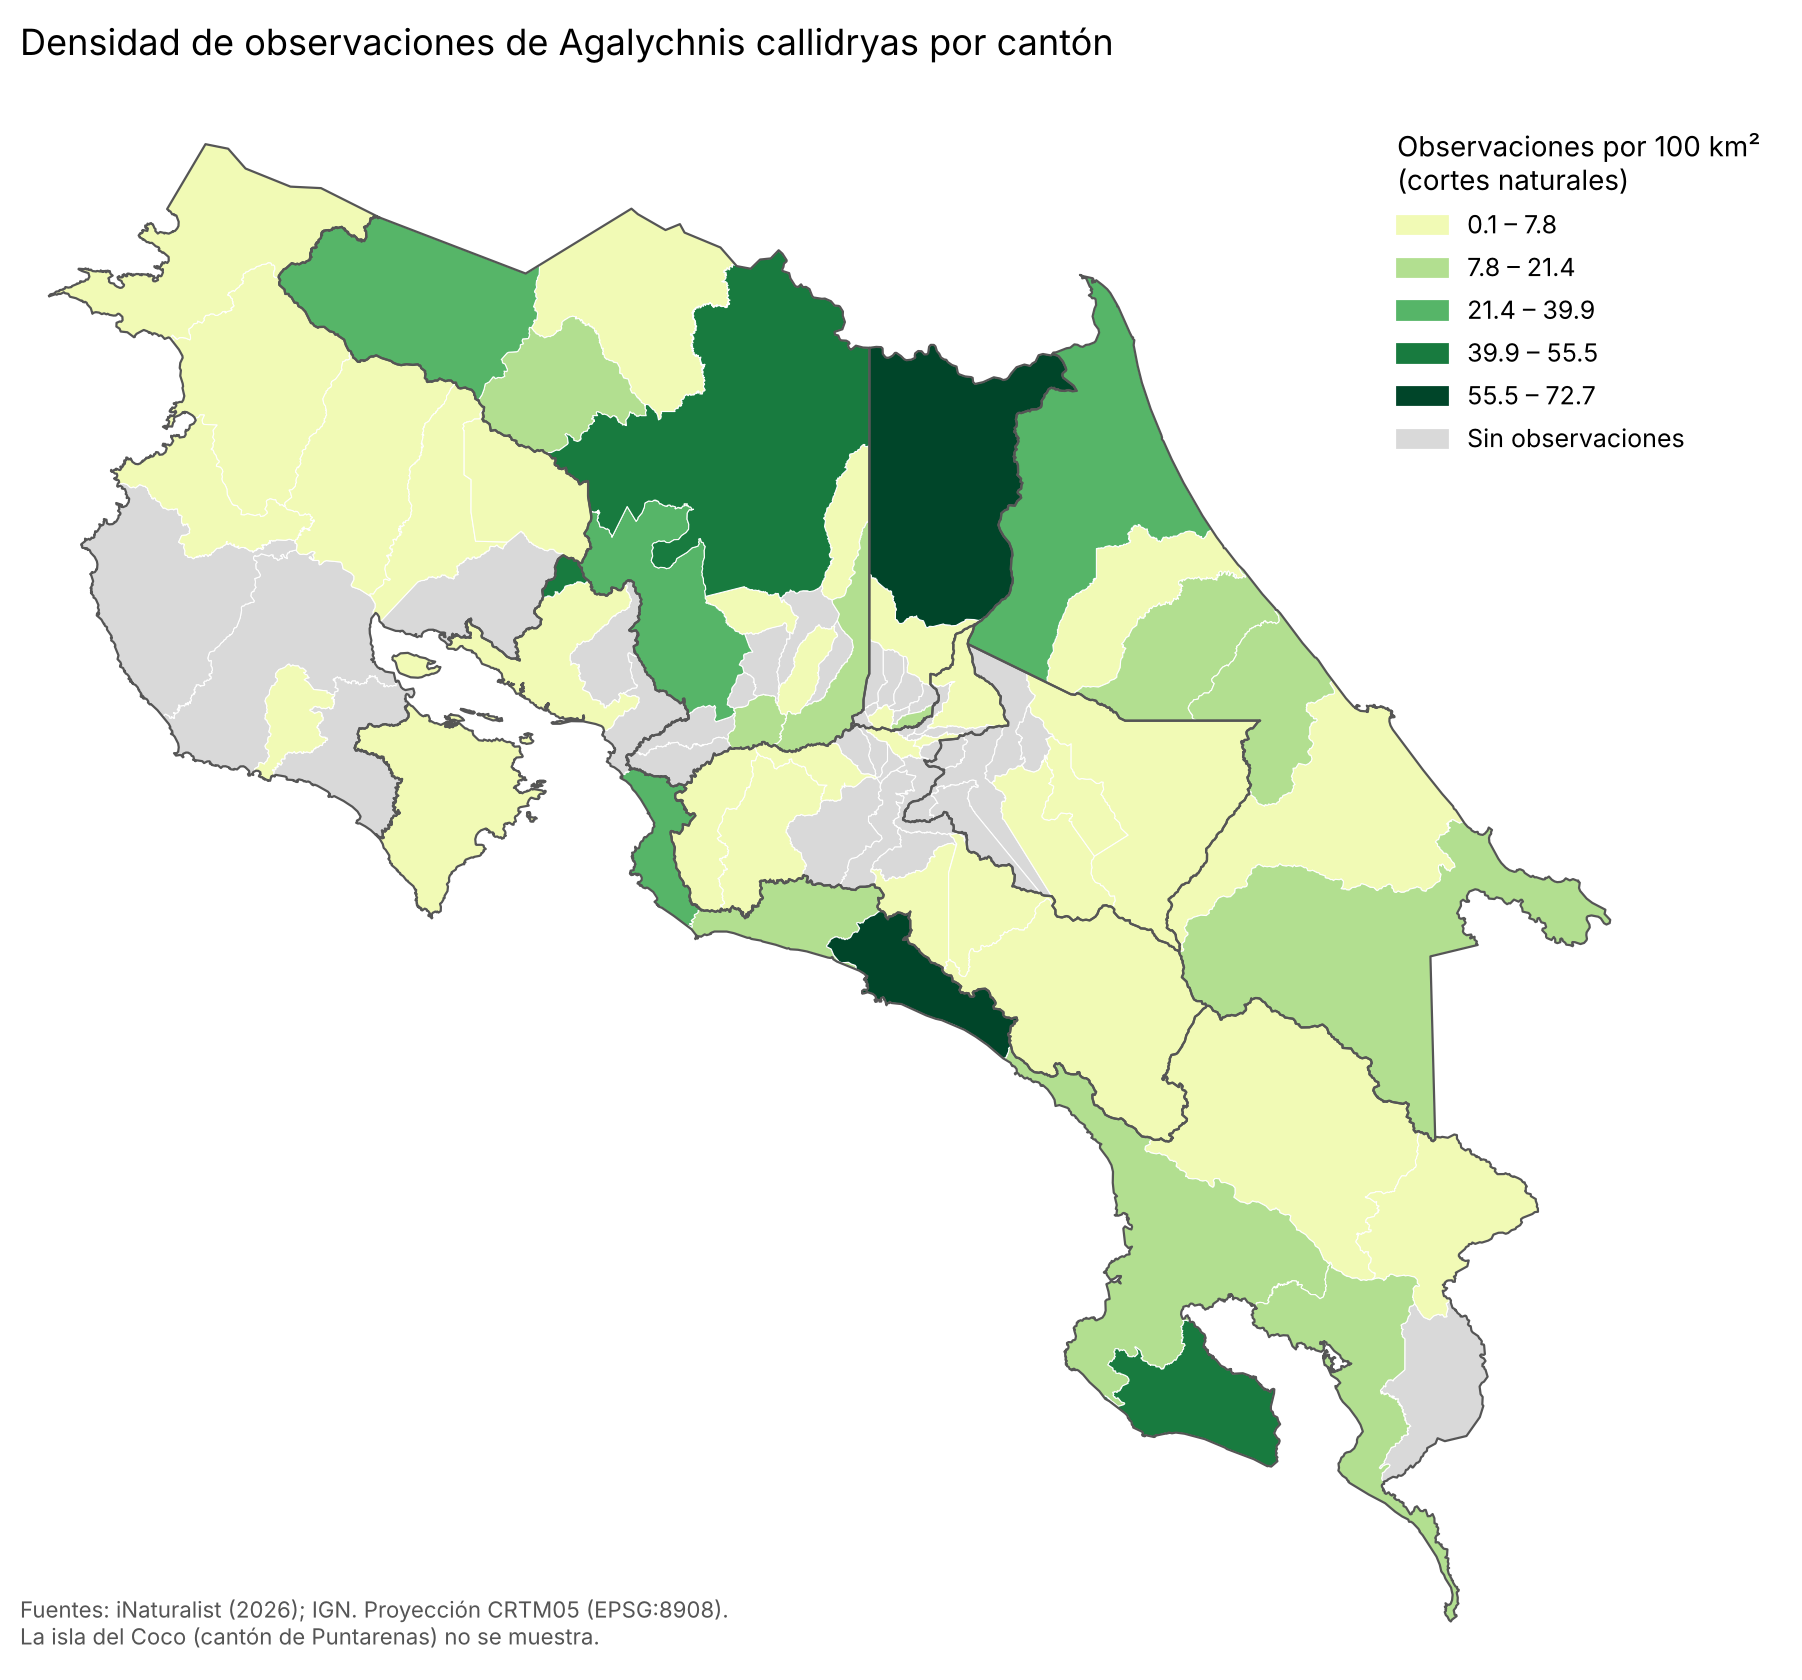

In [12]:
def mapa_coropletas(capa, columna, titulo, etiqueta_leyenda, k=5, cmap="YlGn"):
    '''Mapa de coropletas con Fisher-Jenks; los polígonos con valor 0 o nulo se muestran en gris.'''
    con_datos = capa[capa[columna] > 0].copy()
    sin_datos = capa[~(capa[columna] > 0)]

    # Clasificación por cortes naturales (solo con los polígonos que tienen datos)
    clasif = mapclassify.FisherJenks(con_datos[columna], k=k)
    con_datos["clase"] = clasif.yb
    colores = plt.get_cmap(cmap)(
        [0.15 + 0.85 * i / (k - 1) for i in range(k)])  # tonos de claro a oscuro

    fig, ax = plt.subplots(figsize=(10, 8.5))
    sin_datos.plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.4)
    for i in range(k):
        con_datos[con_datos["clase"] == i].plot(ax=ax, color=colores[i], edgecolor="white", linewidth=0.4)
    provincias.boundary.plot(ax=ax, color="#555555", linewidth=0.8)

    # Leyenda: un rectángulo por clase con su intervalo, más "Sin observaciones"
    limites = [con_datos[columna].min()] + clasif.bins.tolist()
    parches = [mpatches.Patch(color=colores[i], label=f"{limites[i]:.1f} – {limites[i+1]:.1f}") for i in range(k)]
    parches.append(mpatches.Patch(color="#d9d9d9", label="Sin observaciones"))
    ax.legend(handles=parches, title=etiqueta_leyenda, loc="upper right", frameon=False,
              title_fontsize=10, fontsize=9, alignment="left")

    # Encuadre en el territorio continental (la isla del Coco queda fuera de la vista)
    ax.set_xlim(280000, 700000)
    ax.set_ylim(880000, 1250000)
    ax.set_title(titulo, fontsize=13, loc="left")
    ax.annotate("Fuentes: iNaturalist (2026); IGN. Proyección CRTM05 (EPSG:8908).\n"
                "La isla del Coco (cantón de Puntarenas) no se muestra.",
                xy=(0.0, 0.01), xycoords="axes fraction", ha="left", fontsize=8, color="#555555")
    ax.set_axis_off()
    plt.tight_layout()
    return fig, ax

mapa_coropletas(
    cantones_obs, "densidad",
    "Densidad de observaciones de Agalychnis callidryas por cantón",
    "Observaciones por 100 km²\n(cortes naturales)",
)
plt.show()

El mapa muestra que la especie se registra casi exclusivamente en las **vertientes húmedas de tierras bajas**: la zona norte
(Sarapiquí, San Carlos, Upala, Guatuso, Los Chiles), el Caribe (Pococí, Siquirres, Matina, Limón, Talamanca) y el Pacífico Central
y Sur (Quepos, Osa, Golfito, Puerto Jiménez). Las densidades más altas aparecen en cantones con estaciones biológicas o
destinos turísticos muy visitados, como Sarapiquí y Quepos. En gris quedan el **Valle Central** y la **península de Nicoya**, y el resto de Guanacaste tiene densidades mínimas:
la meseta central está por encima del rango altitudinal de la especie y el Pacífico Norte es demasiado seco, un
patrón coherente con su distribución conocida en bosques húmedos por debajo de unos 1000 m.

## 8. Mapa web interactivo

El mapa web se arma con **folium**. Todas las capas se reproyectan a **WGS84 (EPSG:4326)**, el SRC que usa Leaflet. Contiene:

- tres mapas base: OpenStreetMap, Esri gris claro e imágenes satelitales de Esri;
- la capa **"Observaciones por cantón"**, coloreada por el número de registros (cortes naturales), con leyenda y etiquetas
  emergentes con el cantón, la provincia, el conteo y la densidad;
- la capa **"Provincias"** (solo contorno);
- la capa **"Observaciones (iNaturalist)"**, con un círculo por registro, etiqueta con el cantón y la fecha, y una ventana
  emergente con la fecha, el lugar, el observador y la dirección del registro;
- el **control de capas**.

Para aligerar el cuaderno, los polígonos se simplifican con una tolerancia de 100 m antes de pasarlos a folium (no altera
el análisis, solo el dibujo).

In [13]:
def mapa_web(cantones_obs, provincias, puntos_canton):
    '''Mapa web con folium: coropletas por cantón, provincias y puntos de observación (todo en WGS84).'''
    # Simplificar (en metros, CRTM05) y reproyectar a WGS84
    cant = cantones_obs.copy()
    cant["geometry"] = cant.geometry.simplify(100)
    cant = cant.to_crs(SRC_WGS84)
    cant["densidad"] = cant["densidad"].round(1)
    prov = provincias.copy()
    prov["geometry"] = prov.geometry.simplify(100)
    prov = prov.to_crs(SRC_WGS84)
    pts = puntos_canton.to_crs(SRC_WGS84)

    m = folium.Map(location=[9.8, -84.1], zoom_start=8, tiles=None, control_scale=True)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, HERE, Garmin", name="Esri gris claro", show=False,
    ).add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, Maxar, Earthstar Geographics", name="Esri satelital", show=False,
    ).add_to(m)

    # --- Capa 1: coropletas del conteo por cantón ---
    valores = cant.loc[cant["observaciones"] > 0, "observaciones"]
    cortes = mapclassify.FisherJenks(valores, k=5).bins.tolist()
    colores = ["#ffffcc", "#c2e699", "#78c679", "#31a354", "#006837"]
    escala = StepColormap(colores, index=[1] + cortes[:-1], vmin=1, vmax=cortes[-1],
                          caption="Observaciones por cantón (número de registros)")

    def estilo(feature):
        n = feature["properties"]["observaciones"]
        return {"fillColor": escala(n) if n > 0 else "#d9d9d9",
                "color": "white", "weight": 0.6, "fillOpacity": 0.75}

    folium.GeoJson(
        cant[["canton", "provincia", "observaciones", "densidad", "geometry"]],
        name="Observaciones por cantón",
        style_function=estilo,
        highlight_function=lambda f: {"weight": 2.5, "color": "#333333"},
        tooltip=folium.GeoJsonTooltip(
            fields=["canton", "provincia", "observaciones", "densidad"],
            aliases=["Cantón:", "Provincia:", "Observaciones:", "Densidad (obs/100 km²):"],
            localize=True,
        ),
    ).add_to(m)
    escala.add_to(m)

    # --- Capa 2: provincias (contorno) ---
    folium.GeoJson(
        prov[["provincia", "geometry"]], name="Provincias",
        style_function=lambda f: {"fill": False, "color": "#444444", "weight": 1.5},
        tooltip=folium.GeoJsonTooltip(fields=["provincia"], aliases=["Provincia:"]),
    ).add_to(m)

    # --- Capa 3: puntos de observación ---
    # Panel propio con z-index alto para que los puntos queden siempre encima de los polígonos,
    # incluso después de apagar y encender capas en el control de capas
    folium.map.CustomPane("puntos", z_index=650, pointer_events=True).add_to(m)
    pts = pts.assign(fecha=pts["observed_on"].dt.strftime("%Y-%m-%d"),
                     place_guess=pts["place_guess"].fillna("—"))
    marcador = folium.CircleMarker(radius=3, color="#7f0000", weight=0.5,
                                   fill=True, fill_color="#e34a33", fill_opacity=0.85)
    marcador.options["pane"] = "puntos"   # dibujar los círculos en el panel superior
    folium.GeoJson(
        pts[["fecha", "place_guess", "canton", "user_login", "uri", "geometry"]],
        name="Observaciones (iNaturalist)",
        pane="puntos",
        marker=marcador,
        tooltip=folium.GeoJsonTooltip(fields=["canton", "fecha"], aliases=["Cantón:", "Fecha:"]),
        popup=folium.GeoJsonPopup(
            fields=["fecha", "place_guess", "canton", "user_login", "uri"],
            aliases=["Fecha:", "Lugar:", "Cantón:", "Observador:", "Registro:"],
        ),
    ).add_to(m)

    folium.LayerControl(collapsed=False).add_to(m)
    return m

mapa = mapa_web(cantones_obs, provincias, puntos_canton)
mapa

En el mapa interactivo se aprecia la misma estructura del mapa estático, ahora con el detalle de cada registro. Al acercarse,
los puntos revelan **focos muy localizados**: la Estación Biológica La Selva y Puerto Viejo de Sarapiquí,
los alrededores de La Fortuna y el volcán Arenal, Tortuguero en Pococí, Cahuita y Puerto Viejo en Talamanca, Manuel Antonio en
Quepos y la península de Osa. Con el mapa base satelital se observa que los puntos se ubican en zonas de bosque o en el borde
entre bosque y áreas abiertas, cerca de caminos, albergues y ríos, lo que vuelve a señalar el peso del acceso y del turismo
en la distribución de los registros.

## 9. Conclusiones

1. **¿Dónde se concentran las observaciones?** En las tierras bajas húmedas de la zona norte, el Caribe y el Pacífico Central y Sur.
   San Carlos y Sarapiquí son los cantones con más registros y, junto con Pococí, Upala y Talamanca, forman los cinco primeros, que reúnen el 64 % de los registros.
2. **¿Cuántas observaciones hay por unidad de área?** La densidad es muy desigual: es máxima en cantones relativamente pequeños con
   sitios de observación muy visitados (Sarapiquí, Quepos) y nula en casi todo el Valle Central y el Pacífico Norte seco. Menos
   de dos tercios de los cantones del país tienen al menos un registro.
3. **¿Cómo se reparten entre provincias y qué tan concentrado está el esfuerzo?** Alajuela es la provincia con más observaciones,
   seguida de Puntarenas, Heredia y Limón; San José, Cartago y Guanacaste suman muy pocos registros. El esfuerzo está muy
   concentrado: los 5 cantones con más registros reúnen el 64 % de las observaciones y los 10 primeros, el 85 %.

**Limitaciones.**

- Los datos de iNaturalist reflejan el **esfuerzo de observación** (accesibilidad, turismo, ubicación de estaciones biológicas),
  no la abundancia real de la especie: un cantón sin registros no implica ausencia.
- Se excluyeron los registros con coordenadas ocultadas o con precisión mayor a 1 km, por lo que los conteos son un mínimo.
- El cantón es una unidad grande y heterogénea (incluye zonas altas y bajas, bosques y ciudades); la densidad por cantón
  oculta la variación interna. Un análisis más fino podría usar una malla regular o la altitud de cada punto (raster).
- Los límites del IGN están generalizados: algunos puntos de la costa se asignaron con el vecino más cercano (≤ 2 km).

## 10. Referencias

- AmphibiaWeb. (2026). *Agalychnis callidryas: Red-eyed treefrog*. University of California, Berkeley. https://amphibiaweb.org/cgi/amphib_query?where-genus=Agalychnis&where-species=callidryas
- python-visualization. (2026). *folium* [Software]. https://python-visualization.github.io/folium/
- iNaturalist. (2026). *Observaciones de* Agalychnis callidryas *en Costa Rica* [Conjunto de datos]. https://www.inaturalist.org/observations?place_id=6924&taxon_id=23702
- Instituto Geográfico Nacional. (2026). *Límites cantonales y provinciales de Costa Rica* [Conjunto de datos]. Repositorio del curso GF-0657. https://github.com/gf0657-programacionsig/2026-ii
- Jordahl, K., Van den Bossche, J., Fleischmann, M., & colaboradores. (2026). *geopandas* [Software]. https://geopandas.org
- Rey, S. J., Arribas-Bel, D., & Wolf, L. J. (2023). *Geographic data science with Python*. CRC Press. https://geographicdata.science/book/

## 11. Declaración de uso de asistentes de inteligencia artificial

Se utilizó el asistente de IA **Claude (Anthropic)** como apoyo para: estructurar el cuaderno; generar y depurar el código de
preparación de la capa de puntos, de la unión espacial (incluido el uso de `sjoin_nearest` para los puntos costeros), de la
agregación con `dissolve()` y de los mapas estático y web; y redactar un primer borrador del texto interpretativo. El código y los
resultados fueron revisados, ejecutados y verificados por el autor, que comprende y puede explicar cada parte del cuaderno.